# Лабораторна робота 1. Цуркан Еріка. Варіант 7 (17)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [13]:
readings = pd.read_parquet("meters.parquet")
customers = pd.read_csv("registry.csv")

readings.info()
display(readings.head())

customers.info()
display(customers.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 516214 entries, 0 to 516213
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   meter_id         516214 non-null  object        
 1   ts               516214 non-null  datetime64[us]
 2   consumption_kwh  516214 non-null  float64       
 3   record_ts        516214 non-null  datetime64[us]
dtypes: datetime64[us](2), float64(1), object(1)
memory usage: 15.8+ MB


,meter_id,ts,consumption_kwh,record_ts
0,UA101476,2026-01-05 00:00:00,1827.3,2026-01-05 00:08:04
1,UA101476,2026-01-05 01:00:00,1709.5,2026-01-05 01:12:38
2,UA101476,2026-01-05 02:00:00,1799.1,2026-01-05 02:10:58
3,UA101476,2026-01-05 03:00:00,1818.5,2026-01-05 03:03:21
4,UA101476,2026-01-05 04:00:00,2022.8,2026-01-05 04:13:45


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   meter_id          800 non-null    object
 1   customer_type     800 non-null    object
 2   tariff            800 non-null    object
 3   electric_heating  800 non-null    int64 
 4   connection_year   800 non-null    int64 
 5   years_connected   800 non-null    int64 
 6   district          800 non-null    object
dtypes: int64(3), object(4)
memory usage: 43.9+ KB


,meter_id,customer_type,tariff,electric_heating,connection_year,years_connected,district
0,UA101476,household,dual_zone,1,1998,28,Obolon
1,UA101604,small_business,single,0,2005,21,Sviatoshyn
2,UA102933,household,dual_zone,0,2015,10,Darnytsia
3,UA103017,household,single,0,1996,30,Solomianka
4,UA103109,small_business,single,0,2005,21,Sviatoshyn


In [14]:
## 2. Звірка з описом
#Перевіряємо категорії, межі й кількість лічильників.

period_start = pd.Timestamp("2026-01-05 00:00")
period_end = pd.Timestamp("2026-02-01 23:00")

checks = {
    "невідомий customer_type": ~customers["customer_type"].isin(["household", "small_business", "industrial"]),
    "невідомий tariff": ~customers["tariff"].isin(["single", "dual_zone"]),
    "electric_heating не 0/1": ~customers["electric_heating"].isin([0, 1]),
    "connection_year поза межами": ~customers["connection_year"].between(1985, 2024),
    "years_connected поза межами": ~customers["years_connected"].between(1, 41),
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

print("ts поза періодом:", (~readings["ts"].between(period_start, period_end)).sum())
print("лічильників:", readings["meter_id"].nunique(), "і", customers["meter_id"].nunique())
display(readings["consumption_kwh"].describe())

невідомий customer_type: 0
невідомий tariff: 0
electric_heating не 0/1: 0
connection_year поза межами: 0
years_connected поза межами: 0
ts поза періодом: 0
лічильників: 800 і 800


,consumption_kwh
count,516214.000000
mean,237.310519
std,2182.738692
min,0.023100
25%,0.389300
50%,0.852700
75%,2.632800
max,90672.300000


In [15]:
## 3. Номери й райони (D-E, D-F)
# треба номера з UA та шестизначне згідно районів

bad_ids = customers.loc[~customers["meter_id"].str.fullmatch(r"UA\d{6}"), "meter_id"]
print("D-E:", len(bad_ids), "зіпсованих номерів, наприклад", bad_ids.head(5).tolist())
customers["meter_id"] = customers["meter_id"].str.extract(r"(UA\d{6})", expand=False)

district_names = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
bad_districts = customers.loc[~customers["district"].isin(district_names), "district"]
print("D-F:", len(bad_districts), "рядків, варіанти:", sorted(bad_districts.unique()))
customers["district"] = customers["district"].str.strip().str.title()

print("лишилось поганих номерів:", (~customers["meter_id"].str.fullmatch(r"UA\d{6}")).sum())
print("лишилось поганих районів:", (~customers["district"].isin(district_names)).sum())

D-E: 96 зіпсованих номерів, наприклад ['00UA113888', ' UA138607', 'UA144598 ', 'UA148561 ', '00UA173852']
D-F: 80 рядків, варіанти: ['DARNYTSIA', 'Darnytsia ', 'OBOLON', 'Obolon ', 'PODIL', 'Podil ', 'SOLOMIANKA', 'SVIATOSHYN', 'Solomianka ', 'Sviatoshyn ', 'darnytsia', 'obolon', 'podil', 'solomianka', 'sviatoshyn']
лишилось поганих номерів: 0
лишилось поганих районів: 0


In [16]:
##4. Приєднуємо реєстр до показників та робим тест, що кожен рядок знайшов абонента.

data = readings.merge(customers, on="meter_id", how="left", validate="m:1", indicator=True)

print("рядків було:", len(readings), "| стало:", len(data))
print(data["_merge"].value_counts())
data = data.drop(columns="_merge")

рядків було: 516214 | стало: 516214
_merge
both          516214
left_only          0
right_only         0
Name: count, dtype: int64


In [17]:
##5.  (D-C)
#Лишаємо по одному запису на лічильник з найпізнішим record_ts.

per_hour = data.groupby(["meter_id", "ts"]).size()
print("D-C: рядків", len(data), "| пар лічильник-година", len(per_hour), "| пар з повтором", (per_hour > 1).sum())

latest = data.groupby(["meter_id", "ts"])["record_ts"].idxmax()
data = data.loc[latest].reset_index(drop=True)
print("після зняття повторів:", len(data))

D-C: рядків 516214 | пар лічильник-година 516214 | пар з повтором 0
після зняття повторів: 516214


D-D: 64 лічильників у Вт·год
у звичайних максимум: 4.76
у Вт·год мінімум: 231.36


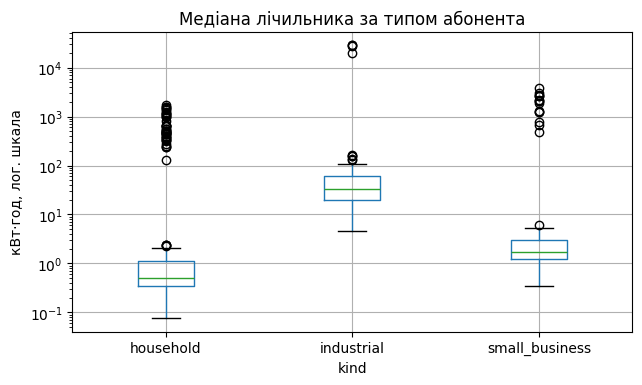

поза межами після ділення: 0


In [18]:
## 6. Вт*год замість кВт*год (D-D)
#Надто сильна різниця в медіанах. Тому ми ділимо його значення на 1000.

meter_stats = data.groupby("meter_id").agg(
    med=("consumption_kwh", "median"),
    kind=("customer_type", "first"),
)
kind_med = data.groupby("customer_type")["consumption_kwh"].median()
meter_stats["times"] = meter_stats["med"] / meter_stats["kind"].map(kind_med)

in_wh = meter_stats.index[meter_stats["times"] > 100]
print("D-D:", len(in_wh), "лічильників у Вт·год")
print("у звичайних максимум:", round(meter_stats.loc[meter_stats["times"] <= 100, "times"].max(), 2))
print("у Вт·год мінімум:", round(meter_stats.loc[meter_stats["times"] > 100, "times"].min(), 2))

meter_stats.boxplot(column="med", by="kind", figsize=(7, 4))
plt.yscale("log")
plt.suptitle("")
plt.title("Медіана лічильника за типом абонента")
plt.ylabel("кВт·год, лог. шкала")
plt.show()

data["consumption_kwh"] = np.where(data["meter_id"].isin(in_wh),
                                   data["consumption_kwh"] / 1000,
                                   data["consumption_kwh"])

limits = pd.DataFrame({"customer_type": ["household", "small_business", "industrial"],
                       "lo": [0.01, 0.02, 1], "hi": [10, 60, 1200]})
bounds = data[["customer_type"]].merge(limits, on="customer_type", how="left")
outside = (data["consumption_kwh"] < bounds["lo"]) | (data["consumption_kwh"] > bounds["hi"])
print("поза межами після ділення:", outside.sum())

In [19]:
## 7. (D-A)
# Якщо останній запис > 48 до кінця періода = замовк

hours_quiet = (period_end - data.groupby("meter_id")["ts"].max()).dt.total_seconds() / 3600

silent = hours_quiet[hours_quiet > 48].index.tolist()
print("D-A:", len(silent), "замовклих")
print("у решти тиша до", hours_quiet[hours_quiet <= 48].max(), "год, у замовклих від", hours_quiet[hours_quiet > 48].min(), "год")

D-A: 48 замовклих
у решти тиша до 1.0 год, у замовклих від 142.0 год


D-B: 40 завмерлих
у решти від 0.8404 | у завмерлих до 0.4947


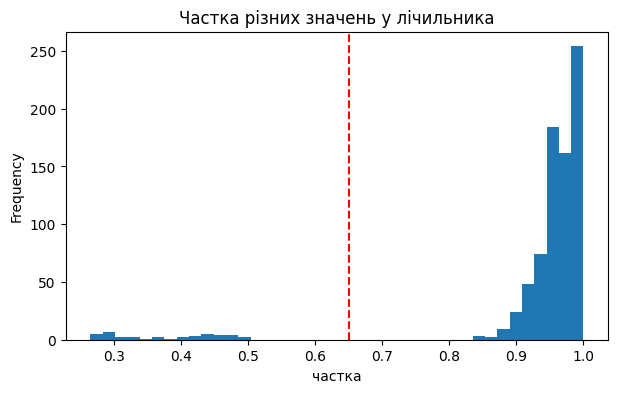

In [20]:
## 8. (D-B)
#Частка різних значень серед записів лічильника, якщо < 0.65 = завмер.

variety = data.groupby("meter_id")["consumption_kwh"].agg(lambda values: values.nunique() / len(values))

frozen = variety[variety < 0.65].index.tolist()
print("D-B:", len(frozen), "завмерлих")
print("у решти від", round(variety[variety >= 0.65].min(), 4), "| у завмерлих до", round(variety[variety < 0.65].max(), 4))

variety.plot(kind="hist", bins=40, figsize=(7, 4), title="Частка різних значень у лічильника")
plt.axvline(0.65, color="red", linestyle="--")
plt.xlabel("частка")
plt.show()

In [21]:
## 9. Колонки-копії
#Пари з |кореляцією| > 0.95 => прибираємо другу колонку пари та record_ts.
corr_abs = data.select_dtypes("number").corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1)).stack()
copy_pairs = upper[upper > 0.95]
print(copy_pairs)

result = data.drop(columns=["record_ts"] + [second for first, second in copy_pairs.index])
print("колонки:", result.columns.tolist())

connection_year  years_connected    0.999129
dtype: float64
колонки: ['meter_id', 'ts', 'consumption_kwh', 'customer_type', 'tariff', 'electric_heating', 'connection_year', 'district']


In [22]:
## Double-check

districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (516214, 8)


In [23]:
## Регресія.
# Вплив електроопалення й двозонного тарифу на добове споживання домогосподарств.

skip = set(silent) | set(frozen)
homes = result[(result["customer_type"] == "household") & ~(result["meter_id"].isin(skip))]

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("лічильників:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

лічильників: 481
a = 10.39, b₁ (опалення) = 19.09, b₂ (двозонний тариф) = 2.61, R² = 0.725
